# SPARCS 2023 sepsis benchmarking

**Question:** which NY hospitals have more sepsis deaths than expected, given how sick their patients are?

**Plan:**
0. Setup
1. Load, explore, clean, build the cohort
2. EDA (including why raw death rates are misleading)
3. Risk models: patient-level P(death) at an average hospital
4. Calibration
5. Hospital observed vs expected (O/E) and funnel plot
6. Sensitivity analyses
7. Fairness check

Column names follow the Socrata API (lowercase_with_underscores); see `DATA_DICTIONARY.md`. Cleaning and cohort rules live in `src/clean.py`.

<!-- apr_drg_code: The All Patients Refined Diagnosis Related Groups (APR-DRG) Classification Code.
apr_drg_description: The APR-DRG Classification Code Description. -->


## 0. Setup
Imports, dataset settings, and folders for cached data and figures.

In [22]:
# Data handling and plotting
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# Modelling and evaluation
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Our cleaning and cohort rules
from src.clean import build_cohort, clean

# Which data to pull
DATASET_ID = "46xm-urtu"  # Hospital Inpatient Discharges (SPARCS De-Identified): 2023
APR_DRG = "720"           # Septicemia & disseminated infections (194 = heart failure)

# Where to cache the download and save figures
DATA = Path("data"); DATA.mkdir(exist_ok=True)
FIGS = Path("figs"); FIGS.mkdir(exist_ok=True)
RAW_PATH = DATA / f"sparcs_2023_drg{APR_DRG}.parquet"

## 1. Load, explore, clean, build the cohort

### 1a. Load the raw data
Download once from the SPARCS API, then read the local Parquet copy.

In [23]:
# Download only if there is no local copy yet
if not RAW_PATH.exists():
    # ~131k sepsis discharges in 2023; one request, takes a minute or two.
    url = (
        f"https://health.data.ny.gov/resource/{DATASET_ID}.csv"
        f"?apr_drg_code={APR_DRG}&$limit=500000"
    )
    # Read everything as text; clean() converts the numeric columns
    raw = pd.read_csv(url, dtype=str)
    raw.to_parquet(RAW_PATH, index=False)

raw = pd.read_parquet(RAW_PATH)
print(raw.shape)
print(sorted(raw.columns))

(131139, 33)
['age_group', 'apr_drg_code', 'apr_drg_description', 'apr_mdc_code', 'apr_mdc_description', 'apr_medical_surgical', 'apr_risk_of_mortality', 'apr_severity_of_illness', 'apr_severity_of_illness_code', 'birth_weight', 'ccsr_diagnosis_code', 'ccsr_diagnosis_description', 'ccsr_procedure_code', 'ccsr_procedure_description', 'discharge_year', 'emergency_department_indicator', 'ethnicity', 'facility_name', 'gender', 'hospital_county', 'hospital_service_area', 'length_of_stay', 'operating_certificate_number', 'patient_disposition', 'payment_typology_1', 'payment_typology_2', 'payment_typology_3', 'permanent_facility_id', 'race', 'total_charges', 'total_costs', 'type_of_admission', 'zip_code_3_digits']


### 1b. Explore the raw columns
Check each column's type, missingness and values before deciding what `clean()` should fix. Findings are noted at the top of `src/clean.py`.

In [24]:
# Show every column when printing wide tables
pd.set_option('display.max_columns', None)

In [25]:
raw.columns

Index(['hospital_service_area', 'hospital_county',
       'operating_certificate_number', 'permanent_facility_id',
       'facility_name', 'age_group', 'zip_code_3_digits', 'gender', 'race',
       'ethnicity', 'length_of_stay', 'type_of_admission',
       'patient_disposition', 'discharge_year', 'ccsr_diagnosis_code',
       'ccsr_diagnosis_description', 'ccsr_procedure_code',
       'ccsr_procedure_description', 'apr_drg_code', 'apr_drg_description',
       'apr_mdc_code', 'apr_mdc_description', 'apr_severity_of_illness_code',
       'apr_severity_of_illness', 'apr_risk_of_mortality',
       'apr_medical_surgical', 'payment_typology_1', 'payment_typology_2',
       'payment_typology_3', 'birth_weight', 'emergency_department_indicator',
       'total_charges', 'total_costs'],
      dtype='str')

In [26]:
def column_stats(df: pd.DataFrame, col: str, top: int = 15) -> None:
    s = df[col]
    print(f"=== {col} | dtype: {s.dtype}")
    print(f"missing: {s.isna().sum():,} ({s.isna().mean():.1%})")
    print(f"unique values: {s.nunique(dropna=True):,}")

    # handle the numeric cols
    if pd.api.types.is_numeric_dtype(s):
        print(f"min = {s.min()}")
        print(f"max = {s.max()}")
        print("summary:", s.describe().round(2).to_dict())

        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        outliers = s[(s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)]
        print(f"IQR outliers: {len(outliers):,}")

    # handle the non-numeric cols
    else:
        counts = s.value_counts(dropna=False)
        frequencies = pd.DataFrame({
            "n": counts,
            "percent": (counts / len(s) * 100).round(2),
        })
        print("most frequent values:")
        print(frequencies.head(top))

        # Diagnose strings that may represent numbers.
        as_num = pd.to_numeric(
            s.astype("string").str.replace(",", "", regex=False),
            errors="coerce",
        )
        if as_num.notna().mean() > 0.5:
            invalid = s[as_num.isna() & s.notna()]
            print("mostly numeric strings")
            print("values that do not convert:", invalid.value_counts().to_dict())

    print()

In [27]:
column_stats(raw, 'apr_risk_of_mortality')

=== apr_risk_of_mortality | dtype: str
missing: 0 (0.0%)
unique values: 4
most frequent values:
                           n  percent
apr_risk_of_mortality                
Extreme                58303    44.46
Major                  40943    31.22
Moderate               19016    14.50
Minor                  12877     9.82



### 1c. Clean and build the cohort
`clean()` fixes types and adds the two outcomes; it drops no rows.
`build_cohort()` applies the exclusions in order and counts what's left after each one:
1. No facility id (redacted records can't be benchmarked)
2. Children (0 to 17)
3. Transfers out to another hospital (final outcome unknown)
4. Left against medical advice (care cut short, outcome unknown)

Outcomes:
- `died`: died in hospital ("Expired")
- `died_or_hospice`: died, or discharged to hospice. Used as a sensitivity check, since hospitals differ in how often dying patients go to hospice.

In [28]:
# Fix types, add outcomes, then apply the cohort exclusions
df, cohort_steps = build_cohort(clean(raw))

# CONSORT-style table: rows left after each exclusion
print(cohort_steps)
print(f"Cohort: {len(df):,} discharges, {df.permanent_facility_id.nunique()} hospitals, "
      f"mortality {df.died.mean():.1%}, died or hospice {df.died_or_hospice.mean():.1%}")

                                        step       n
0                      all sepsis discharges  131139
1                        facility identified  131046
2                                     adults  128637
3  not transferred to another acute hospital  125513
Cohort: 125,513 discharges, 186 hospitals, mortality 12.1%, died or hospice 15.9%


## 2. EDA
How does mortality vary with severity, and how big are the hospitals?

                                  n  mortality  median_cost  median_los
apr_severity_of_illness_code                                           
1                              4272   0.002107     7812.635         3.0
2                             24675   0.005268    10354.770         4.0
3                             43593   0.044824    16720.120         5.0
4                             52973   0.248240    29672.190         8.0


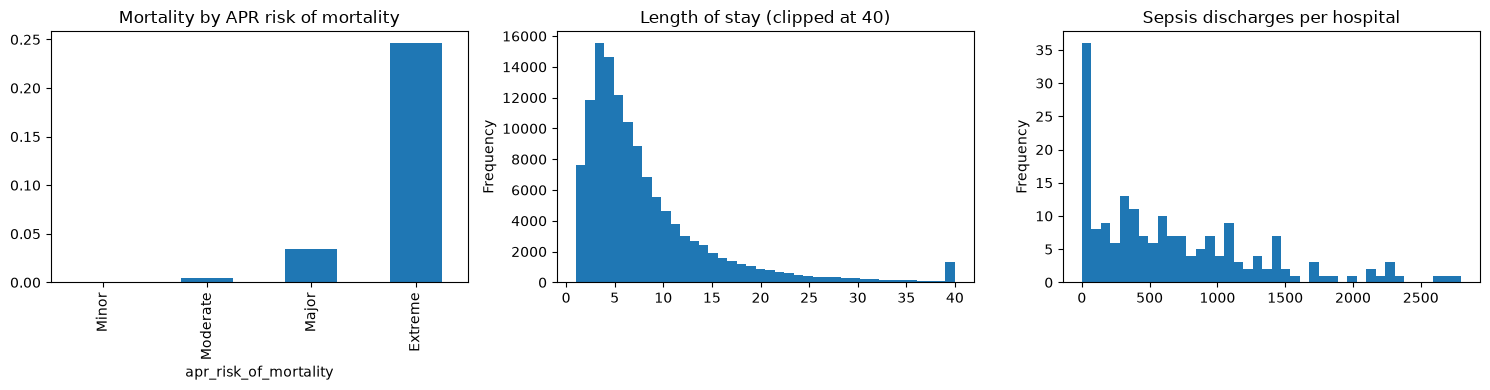

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Mortality rises steeply with APR risk of mortality
df.groupby("apr_risk_of_mortality")["died"].mean().sort_values().plot.bar(ax=axes[0], title="Mortality by APR risk of mortality")

# Length of stay is right-skewed; clip the long tail so the shape is visible
df["length_of_stay"].clip(upper=40).plot.hist(bins=40, ax=axes[1], title="Length of stay (clipped at 40)")

# Hospital size: many small hospitals, whose O/E will be noisy
df.groupby("permanent_facility_id").size().plot.hist(bins=40, ax=axes[2], title="Sepsis discharges per hospital")

plt.tight_layout(); plt.savefig(FIGS / "eda.png", dpi=150)

# Mortality, cost and LOS by severity of illness (1 = minor, 4 = extreme)
print(df.groupby("apr_severity_of_illness_code").agg(n=("died", "size"), mortality=("died", "mean"),
                                                     median_cost=("total_costs", "median"),
                                                     median_los=("length_of_stay", "median")))

### 2a. Why not just compare raw death rates?
Hospitals see different patients. If a hospital's raw mortality mostly follows its share of very sick patients, ranking hospitals on raw rates measures case mix, not care. That's what risk adjustment fixes.

In [30]:
# Per hospital: raw mortality and share of patients with Extreme risk of mortality
case_mix = (df.assign(extreme=df["apr_risk_of_mortality"].eq("Extreme"))
              .groupby(["permanent_facility_id", "facility_name"])
              .agg(n=("died", "size"), raw_mortality=("died", "mean"),
                   share_extreme=("extreme", "mean")))

# Small hospitals have noisy rates; keep those with 300+ sepsis cases for this comparison
case_mix = case_mix[case_mix["n"] >= 300]
corr = case_mix["raw_mortality"].corr(case_mix["share_extreme"])
print(f"{len(case_mix)} hospitals with 300+ cases; "
      f"correlation of raw mortality with share Extreme = {corr:.2f}")

# Hospitals with the least and most severe patient mix
by_severity = case_mix.sort_values("share_extreme")
pd.concat([by_severity.head(3), by_severity.tail(3)]).round(3)

125 hospitals with 300+ cases; correlation of raw mortality with share Extreme = 0.51


,,n,raw_mortality,share_extreme
permanent_facility_id,facility_name,,,
000671,Geneva General Hospital,391,0.110,0.307
000628,UPSTATE University Hospital at Community General,775,0.045,0.317
000818,Saratoga Hospital,982,0.100,0.325
001165,Jacobi Medical Center,846,0.188,0.584
001738,Richmond University Medical Center,511,0.231,0.642
003975,New York-Presbyterian Hospital - Allen Hospital,756,0.163,0.647


## 3. Risk models
Predict each patient's chance of dying at an average NY hospital, from patient factors only.

In [31]:
# Feature sets. Hospital is NOT a feature: the model estimates risk at an average
# hospital, and hospital differences show up later as O/E.
# Race is excluded here and used for the fairness check (step 7).
BASE_FEATURES = ["age_group", "gender", "type_of_admission",
                 "emergency_department_indicator", "apr_severity_of_illness_code"]
FEATURE_SETS = {
    "full": BASE_FEATURES + ["apr_risk_of_mortality"],
    "no_rom": BASE_FEATURES,  # sensitivity: ROM can absorb complications
    "full_plus_payer": BASE_FEATURES + ["apr_risk_of_mortality", "payment_typology_1"],
}

# Outcome, and the hospital each patient belongs to (used to split the folds)
y = df["died"].to_numpy()
groups = df["permanent_facility_id"].to_numpy()
gkf = GroupKFold(n_splits=5)

def oof_predict(make_model, X, target=None):
    """Out-of-fold predictions split by hospital: each hospital is scored by a
    model that never saw any of its patients."""
    target = y if target is None else target
    pred = np.zeros(len(X))
    for tr, te in gkf.split(X, target, groups):
        m = make_model().fit(X.iloc[tr], target[tr])
        pred[te] = m.predict_proba(X.iloc[te])[:, 1]
    return pred

def logreg(cols):
    """Main model: one-hot encode the categories, then logistic regression."""
    pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cols)])
    return lambda: Pipeline([("pre", pre), ("lr", LogisticRegression(max_iter=2000))])

def lgbm():
    """Comparison model: can it beat logistic regression by finding interactions?"""
    return lgb.LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=31,
                              min_child_samples=50, verbose=-1)

# Fit logistic regression on every feature set, LightGBM on the full set only
preds, rows = {}, []
for name, cols in FEATURE_SETS.items():
    # All inputs are categories; a missing value becomes its own category
    X = df[cols].fillna("Unknown").astype(str)
    preds[f"lr_{name}"] = oof_predict(logreg(cols), X)
    if name == "full":
        Xc = X.astype("category")
        preds["lgbm_full"] = oof_predict(lgbm, Xc)

# Discrimination (AUROC, AUPRC) and overall accuracy of the probabilities (Brier)
for name, p in preds.items():
    rows.append({"model": name, "auroc": roc_auc_score(y, p),
                 "auprc": average_precision_score(y, p), "brier": brier_score_loss(y, p)})
metrics = pd.DataFrame(rows).round(4)
print(metrics)
metrics.to_csv(FIGS / "model_metrics.csv", index=False)

                model   auroc   auprc   brier
0             lr_full  0.8135  0.2976  0.0913
1           lgbm_full  0.8128  0.2933  0.0912
2           lr_no_rom  0.7900  0.2721  0.0937
3  lr_full_plus_payer  0.8133  0.2979  0.0914


## 4. Calibration
Do predicted risks match what actually happened? This matters more than AUROC here, because expected deaths are sums of predicted probabilities.

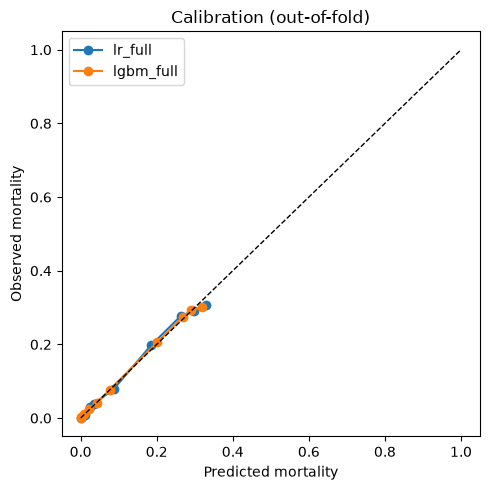

In [32]:
plt.figure(figsize=(5, 5))

# Bin patients into deciles of predicted risk; compare mean predicted vs observed mortality
for name in ["lr_full", "lgbm_full"]:
    frac, mean = calibration_curve(y, preds[name], n_bins=10, strategy="quantile")
    plt.plot(mean, frac, marker="o", label=name)

# Perfect calibration falls on the diagonal
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("Predicted mortality"); plt.ylabel("Observed mortality"); plt.legend()
plt.title("Calibration (out-of-fold)"); plt.tight_layout()
plt.savefig(FIGS / "calibration.png", dpi=150)

## 5. Hospital observed vs expected (O/E) and funnel plot
- Observed (O) = actual deaths; expected (E) = sum of patients' predicted risks.
- O/E above 1 means more deaths than the patient mix explains.
- Small hospitals vary a lot by chance, so flags use Poisson limits around E (95% warning, 99.8% alarm).

flag
within          113
high (99.8%)     28
low (99.8%)      19
high (95%)       16
low (95%)        10
Name: count, dtype: int64


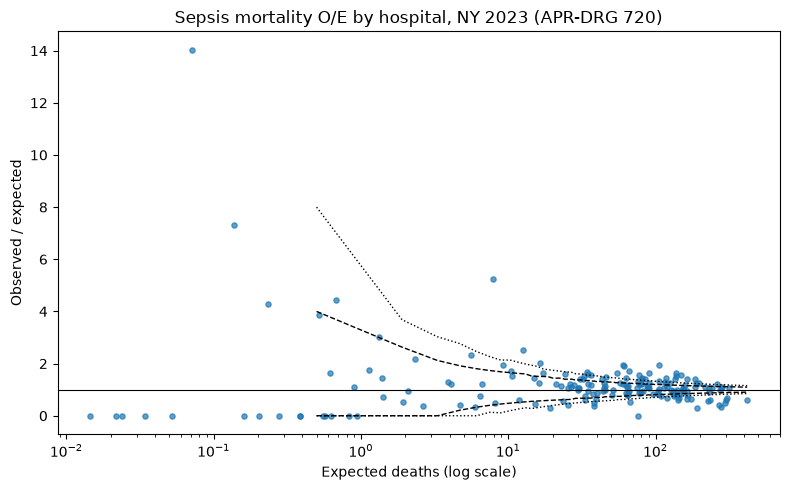

In [33]:
def hospital_oe(p, outcome="died"):
    """Observed vs expected deaths per hospital, with a funnel-plot flag."""
    # Roll patients up to hospitals: O = sum of outcomes, E = sum of predicted risks
    h = (df.assign(p=p, o=df[outcome]).groupby(["permanent_facility_id", "facility_name"])
           .agg(n=("o", "size"), observed=("o", "sum"), expected=("p", "sum"))
           .reset_index())
    h["oe"] = h["observed"] / h["expected"]

    # Range of death counts a hospital with E expected deaths would see by chance alone
    e = h["expected"].to_numpy()[:, None]
    lo95, hi95 = stats.poisson.ppf([0.025, 0.975], e).T
    lo998, hi998 = stats.poisson.ppf([0.001, 0.999], e).T

    # Check the stricter limit first so each hospital gets its strongest flag
    h["flag"] = np.select(
        [h.observed > hi998, h.observed < lo998, h.observed > hi95, h.observed < lo95],
        ["high (99.8%)", "low (99.8%)", "high (95%)", "low (95%)"], default="within")
    return h

# O/E from the main model
hosp = hospital_oe(preds["lr_full"])
print(hosp["flag"].value_counts())
hosp.sort_values("oe", ascending=False).to_csv(FIGS / "hospital_oe.csv", index=False)

# Funnel plot: O/E against hospital size (expected deaths), with control limits
e = np.linspace(max(hosp.expected.min(), 0.5), hosp.expected.max(), 300)
plt.figure(figsize=(8, 5))
plt.scatter(hosp.expected, hosp.oe, s=14, alpha=0.7)
for (a, b), style in [((0.025, 0.975), "--"), ((0.001, 0.999), ":")]:
    plt.plot(e, stats.poisson.ppf(a, e) / e, "k" + style, lw=1)
    plt.plot(e, stats.poisson.ppf(b, e) / e, "k" + style, lw=1)
plt.axhline(1, color="k", lw=0.8)  # O/E = 1: as expected
plt.xscale("log"); plt.xlabel("Expected deaths (log scale)"); plt.ylabel("Observed / expected")
plt.title(f"Sepsis mortality O/E by hospital, NY 2023 (APR-DRG {APR_DRG})")
plt.tight_layout(); plt.savefig(FIGS / "funnel_plot.png", dpi=150)

## 6. Sensitivity analyses
Do the hospital conclusions hold if we change the method?
- Drop APR risk of mortality (it can absorb complications that happened in hospital)
- Add payer
- Count hospice discharges as deaths

In [34]:
# Hospital O/E under each feature set
ranks = pd.DataFrame({k: hospital_oe(preds[f"lr_{k}"]).set_index("permanent_facility_id")["oe"]
                      for k in FEATURE_SETS})

# Refit the main model on the hospice-as-death outcome and add its O/E
y_hosp = df["died_or_hospice"].to_numpy()
cols = FEATURE_SETS["full"]
p_hosp = oof_predict(logreg(cols), df[cols].fillna("Unknown").astype(str), target=y_hosp)
ranks["died_or_hospice"] = hospital_oe(p_hosp, "died_or_hospice").set_index("permanent_facility_id")["oe"]

# Spearman rank correlation: near 1 means hospitals keep roughly the same order
print(ranks.corr(method="spearman").round(3))

# Which hospitals change flag status when hospice counts as death?
flags = pd.DataFrame({
    "died": hospital_oe(preds["lr_full"]).set_index("permanent_facility_id")["flag"],
    "died_or_hospice": hospital_oe(p_hosp, "died_or_hospice").set_index("permanent_facility_id")["flag"],
})
print(pd.crosstab(flags["died"], flags["died_or_hospice"]))

                  full  no_rom  full_plus_payer  died_or_hospice
full             1.000   0.994            1.000            0.902
no_rom           0.994   1.000            0.994            0.895
full_plus_payer  1.000   0.994            1.000            0.903
died_or_hospice  0.902   0.895            0.903            1.000
died_or_hospice  high (95%)  high (99.8%)  low (95%)  low (99.8%)  within
died                                                                     
high (95%)                4             0          0            0      12
high (99.8%)             11            13          0            0       4
low (95%)                 0             0          1            1       8
low (99.8%)               0             0          2           15       2
within                    4             1          2            0     106


## 7. Fairness check
Race is not a model input. Compare observed and expected mortality within each group: O/E near 1 means the model isn't systematically over- or under-predicting risk for that group.

In [35]:
# Mean observed vs mean predicted mortality by race, using the main model
fair = (df.assign(p=preds["lr_full"]).groupby("race")
          .agg(n=("died", "size"), observed=("died", "mean"), expected=("p", "mean")))
fair["oe"] = fair["observed"] / fair["expected"]
print(fair.round(3))

                            n  observed  expected     oe
race                                                    
Black/African American  18607     0.130     0.117  1.119
Multi-racial             1476     0.110     0.125  0.881
Other Race              29847     0.114     0.111  1.019
White                   75583     0.123     0.127  0.967
